# NiftyGEX: the input datasets

**Project question:** traders compress the NIFTY 50 option chain into one number, *gamma exposure* (GEX). Can a model that reads every contract forecast next-day volatility better than that number and standard methods?

This notebook introduces the raw inputs that go into the project:

- what each dataset is and where it lives;
- a few rows of each, exactly as stored;
- a handful of charts showing coverage, scale and one trading day in detail.

The last two sections preview where these inputs end up (a real GEX profile) and the known data gaps.

*Run with the `Python 3.11 (niftygex)` kernel. All paths come from the project config (`configs/paths.local.yaml`); nothing is hard-coded.*

In [2]:
pip install polars


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 865.8/865.8 kB 9.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.3/43.3 MB 10.9 MB/s  0:00:03m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [polars]2m1/2 [polars]

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import json
import sys
from datetime import date, datetime
from pathlib import Path

# Locate the repository root (the folder holding configs/data.yaml) and make the project package importable.
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "data.yaml").exists())
sys.path.insert(0, str(REPO / "src"))

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import polars as pl
from IPython.display import HTML, Markdown, display

from niftygex.config import load_config

CONFIG = load_config()
PATHS = CONFIG["paths"]
RAW, CURATED, EXPOSURE = PATHS["raw_root"], PATHS["curated_root"], PATHS["exposure_root"]
REPORTS, MANIFESTS = PATHS["reports_root"], PATHS["manifests_root"]
DATA_ROOT = PATHS["data_root"]

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)
pl.Config.set_tbl_cols(14)
pl.Config.set_fmt_str_lengths(40)

# Chart style: light surface, text tokens, recessive grid; colors are the validated reference palette.
SURFACE, TEXT, TEXT_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, RED, NEUTRAL = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#8a8984"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT_2, "axes.titlecolor": TEXT, "axes.titlesize": 11,
    "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": TEXT_2, "ytick.color": TEXT_2,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.frameon": False, "legend.fontsize": 9,
    "figure.dpi": 110, "lines.linewidth": 1.6,
})


def show(frame: pd.DataFrame) -> None:
    """Display a table without the index."""
    display(HTML(frame.to_html(index=False, border=0)))


def rel(path: Path) -> str:
    """Path relative to the repository, for display."""
    try:
        return str(Path(path).resolve().relative_to(REPO))
    except ValueError:
        return str(path)


manifest = json.loads((MANIFESTS / "raw_import_manifest.json").read_text())
cleaning = json.loads((REPORTS / "cleaning_report.json").read_text())
print(f"Repository: {REPO.name}   data root: {rel(DATA_ROOT)}   raw files imported: {manifest['file_count']}"
      f"   raw size: {manifest['total_size_bytes'] / 1e6:,.0f} MB")

Repository: NiftyGEX   data root: data   raw files imported: 881   raw size: 378 MB


## 1. The idea in one paragraph

Option market makers hedge with futures. Whether their hedging **damps** moves or **amplifies** them depends on whether they are net long or net short gamma.

For each strike *K*, gamma exposure is

$$\text{GEX}_K = \Gamma_K \times \text{OI}_K \times S^2 \times 0.01,$$

the rupee change in dealer hedging for a 1% move in the index.

Computing it needs:

- per-strike **option prices**, to back out implied volatility and gamma;
- **open interest**;
- the **index and futures** prices, for the forward and the realized-volatility targets;
- **India VIX**, as a control;
- NSE's **participant-wise open interest**, to infer which side dealers are on.

The datasets below supply exactly these.

## 2. Input datasets at a glance

In [4]:
DESCRIPTIONS = {
    "options": ("NIFTY index options", "options/NIFTY/<year>/NIFTY-{call|put}-<expiry>.csv.gz", "5-minute bars",
                "One file per expiry and side (call/put). Each row is one strike at one 5-minute bar: OHLC price, volume, open interest.",
                "Implied volatility, Greeks, GEX, key levels, per-strike tokens"),
    "futures": ("NIFTY futures", "futures/NIFTY/<year>/NIFTY-fut-<expiry>.csv.gz", "5-minute bars",
                "One file per monthly contract: OHLC, volume, open interest.",
                "Front-month price, basis, realized-volatility targets"),
    "equity": ("NIFTY 50 index (spot)", "equity/NIFTY_5minute.csv.gz", "5-minute bars",
               "Index level OHLC (volume is 0 for an index).",
               "Spot for GEX scaling and moneyness"),
    "india_vix": ("India VIX", "india_vix/INDVIX_daily.csv.gz, INDVIX_5minute.csv.gz", "daily + 5-minute",
                  "NSE's 30-day implied-volatility index.",
                  "Control variable and regime slicing"),
    "fiidii": ("Participant-wise open interest (NSE)", "fiidii/participant_oi_2019_to_today.parquet", "daily, after close",
               "Long/short open interest in index and stock futures and options, per client type (Client, DII, FII, Pro, TOTAL).",
               "Inferring the dealer side (sign of GEX)"),
}
rows = []
for key, (name, pattern, grain, contents, used) in DESCRIPTIONS.items():
    source = manifest["sources"][key]
    rows.append({"Dataset": name, "Path (under data/raw/)": pattern, "Files": source["file_count"],
                 "Size (MB)": round(source["total_size_bytes"] / 1e6, 1), "Covers": f"{source['date_min']} → {source['date_max']}",
                 "Granularity": grain, "Contents": contents, "Used for": used})
for name, folder, used in (("NSE bhavcopy (end-of-day OI)", "bhavcopy/", "Reconciling intraday open interest"),):
    present = (RAW / folder).exists() and any((RAW / folder).iterdir())
    rows.append({"Dataset": name, "Path (under data/raw/)": folder, "Files": 0, "Size (MB)": 0.0,
                 "Covers": "available" if present else "not yet available", "Granularity": "daily", "Contents": "Optional input",
                 "Used for": used})
inventory = pd.DataFrame(rows)
show(inventory)

Dataset,Path (under data/raw/),Files,Size (MB),Covers,Granularity,Contents,Used for
NIFTY index options,options/NIFTY/<year>/NIFTY-{call|put}-<expiry>.csv.gz,785,366.2,2019-01-10 → 2026-07-31,5-minute bars,"One file per expiry and side (call/put). Each row is one strike at one 5-minute bar: OHLC price, volume, open interest.","Implied volatility, Greeks, GEX, key levels, per-strike tokens"
NIFTY futures,futures/NIFTY/<year>/NIFTY-fut-<expiry>.csv.gz,91,8.7,2018-11-02 → 2026-07-06,5-minute bars,"One file per monthly contract: OHLC, volume, open interest.","Front-month price, basis, realized-volatility targets"
NIFTY 50 index (spot),equity/NIFTY_5minute.csv.gz,1,2.2,2019-01-01 → 2026-07-31,5-minute bars,Index level OHLC (volume is 0 for an index).,"Spot for GEX scaling, moneyness, the T3 path"
India VIX,"india_vix/INDVIX_daily.csv.gz, INDVIX_5minute.csv.gz",2,0.6,2013-01-01 → 2026-04-24,daily + 5-minute,NSE's 30-day implied-volatility index.,Control variable and regime slicing
Participant-wise open interest (NSE),fiidii/participant_oi_2019_to_today.parquet,2,0.5,2019-01-01 → 2026-07-03,"daily, after close","Long/short open interest in index and stock futures and options, per client type (Client, DII, FII, Pro, TOTAL).",Inferring the dealer side (sign of GEX)
Official NSE closing index,official_closes/,0,0.0,not yet available,daily,Optional input,T1 pinning target (settlement price)
NSE bhavcopy (end-of-day OI),bhavcopy/,0,0.0,not yet available,daily,Optional input,Reconciling intraday open interest


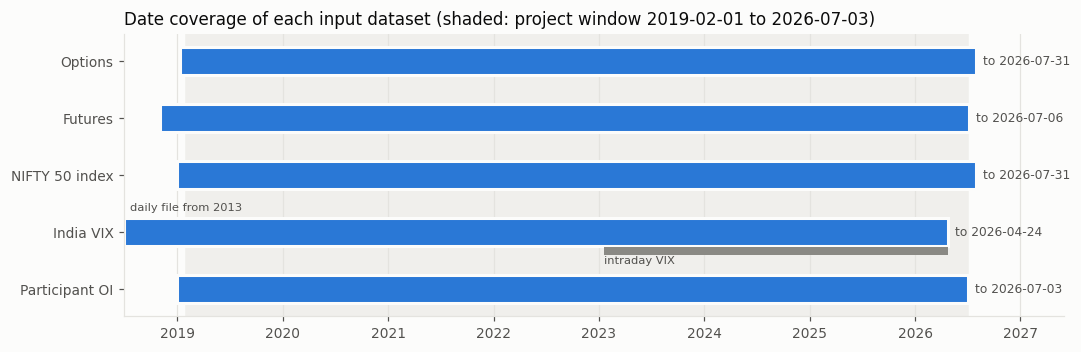

In [5]:
# Coverage timeline: each bar is a dataset's date range; the shaded band is the project's common window.
window = CONFIG["data"]["date_range"]
start, end = pd.Timestamp(str(window["start"])), pd.Timestamp(str(window["end"]))
order = ["fiidii", "india_vix", "equity", "futures", "options"]
labels = {"options": "Options", "futures": "Futures", "equity": "NIFTY 50 index", "india_vix": "India VIX", "fiidii": "Participant OI"}
vix_intraday = pl.read_csv(RAW / "india_vix" / "INDVIX_5minute.csv.gz", columns=["datetime"])["datetime"]

fig, ax = plt.subplots(figsize=(10, 3.3))
ax.axvspan(start, end, color="#f0efec", zorder=0)
for i, key in enumerate(order):
    lo, hi = pd.Timestamp(manifest["sources"][key]["date_min"]), pd.Timestamp(manifest["sources"][key]["date_max"])
    if key == "india_vix":
        # Daily VIX reaches back to 2013; show the project era and mark intraday coverage separately.
        lo = max(lo, pd.Timestamp("2018-07-01"))
    ax.barh(i, (hi - lo).days, left=lo, height=0.5, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=2)
    ax.text(hi + pd.Timedelta(days=25), i, f"to {hi:%Y-%m-%d}", va="center", fontsize=8, color=TEXT_2)
v_lo, v_hi = pd.Timestamp(vix_intraday.min()[:10]), pd.Timestamp(vix_intraday.max()[:10])
ax.barh(order.index("india_vix") - 0.33, (v_hi - v_lo).days, left=v_lo, height=0.14, color=NEUTRAL, zorder=2)
ax.text(v_lo, order.index("india_vix") - 0.55, "intraday VIX", fontsize=7.5, color=TEXT_2)
ax.set_yticks(range(len(order)), [labels[k] for k in order])
ax.grid(axis="y", visible=False)
ax.set_xlim(pd.Timestamp("2018-07-01"), pd.Timestamp("2027-06-01"))
ax.text(pd.Timestamp("2018-07-20"), order.index("india_vix") + 0.38, "daily file from 2013", fontsize=7.5, color=TEXT_2)
ax.set_title(f"Date coverage of each input dataset (shaded: project window {start:%Y-%m-%d} to {end:%Y-%m-%d})")
fig.tight_layout()
plt.show()

## 3. A closer look at each dataset

### 3.1 NIFTY index options

This is the core dataset.

- **File layout:** one compressed CSV per **expiry and side**, for example `NIFTY-call-20260616.csv.gz` (calls expiring 16 June 2026).
- **Rows:** one per 5-minute bar per strike.
- **Open interest:** in index units, always a multiple of the lot size.
- **History:** each expiry carries about the last 3 weeks of trading before it expires.

In [6]:
option_files = sorted((RAW / "options" / "NIFTY").glob("*/*.csv.gz"))
expiries = sorted({p.name.split("-")[-1].removesuffix(".csv.gz") for p in option_files})
print(f"{len(option_files)} option files, {len(expiries)} expiries ({expiries[0]} to {expiries[-1]})")
print("Example files:", ", ".join(p.name for p in option_files[:2]), "...", ", ".join(p.name for p in option_files[-2:]))

SAMPLE_EXPIRY = "20260616"
sample_call = pl.read_csv(RAW / "options" / "NIFTY" / "2026" / f"NIFTY-call-{SAMPLE_EXPIRY}.csv.gz")
print(f"\n{rel(RAW / 'options' / 'NIFTY' / '2026' / f'NIFTY-call-{SAMPLE_EXPIRY}.csv.gz')}: {sample_call.height:,} rows x {sample_call.width} columns")
display(sample_call.head(5).to_pandas())

785 option files, 393 expiries (20190131 to 20260818)
Example files: NIFTY-call-20190131.csv.gz, NIFTY-call-20190214.csv.gz ... NIFTY-put-20260811.csv.gz, NIFTY-put-20260818.csv.gz

data/raw/options/NIFTY/2026/NIFTY-call-20260616.csv.gz: 36,811 rows x 12 columns


,datetime,stock_code,expiry_date,right,strike_price,open,high,low,close,volume,open_interest,date
0,2026-05-26 09:15:00,NIFTY,2026-06-16,Call,24050.0,331.35,331.35,320.05,331.25,780,11245,2026-05-26
1,2026-05-26 09:15:00,NIFTY,2026-06-16,Call,24450.0,168.50,168.50,168.50,168.50,0,7085,2026-05-26
2,2026-05-26 09:15:00,NIFTY,2026-06-16,Call,24350.0,190.00,197.85,190.00,191.00,130,4095,2026-05-26
3,2026-05-26 09:15:00,NIFTY,2026-06-16,Call,24500.0,153.05,153.05,140.00,149.25,6305,93210,2026-05-26
4,2026-05-26 09:15:00,NIFTY,2026-06-16,Call,23800.0,468.45,477.30,463.00,477.30,2145,41340,2026-05-26


In [7]:
# The same file, but one moment in time: the 15:10 bar on 12 June 2026 (available at 15:15, the model's daily snapshot), strikes near the money.
moment = sample_call.filter(pl.col("datetime") == "2026-06-12 15:10:00")
near = moment.filter(pl.col("strike_price").is_between(moment["strike_price"].median() - 300, moment["strike_price"].median() + 300))
display(near.sort("strike_price").select("datetime", "expiry_date", "right", "strike_price", "close", "volume", "open_interest").head(12).to_pandas())

,datetime,expiry_date,right,strike_price,close,volume,open_interest
0,2026-06-12 13:55:00,2026-06-16,Call,23300.0,284.30,1049425,4792255
1,2026-06-12 13:55:00,2026-06-16,Call,23350.0,247.95,1001000,2683265
2,2026-06-12 13:55:00,2026-06-16,Call,23400.0,213.65,3271710,7029425
3,2026-06-12 13:55:00,2026-06-16,Call,23450.0,181.20,2907645,4283565
4,2026-06-12 13:55:00,2026-06-16,Call,23500.0,153.40,9268155,11892855
5,2026-06-12 13:55:00,2026-06-16,Call,23550.0,125.80,4036825,3653260
6,2026-06-12 13:55:00,2026-06-16,Call,23600.0,102.60,5597735,7502885
7,2026-06-12 13:55:00,2026-06-16,Call,23650.0,83.95,2984995,2975960
8,2026-06-12 13:55:00,2026-06-16,Call,23700.0,65.45,4975945,8934770
9,2026-06-12 13:55:00,2026-06-16,Call,23750.0,52.30,1902290,2798770


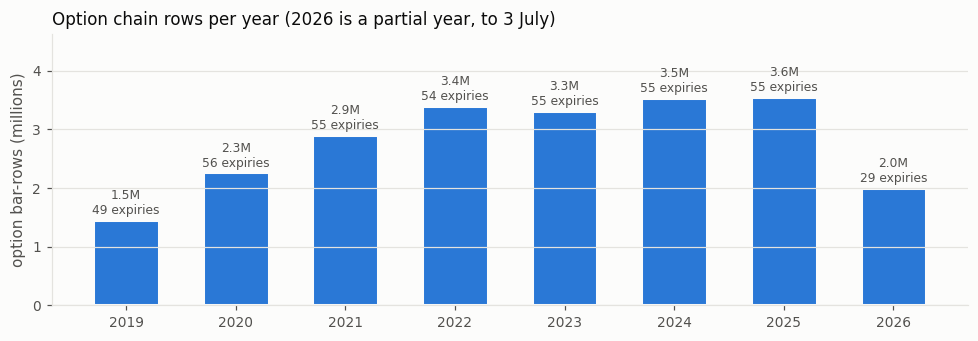

Total: 22,878,869 raw option rows; 22,428,331 after cleaning


In [8]:
# How much option data there is: rows and expiries per year (after cleaning: session filter and dedup).
per_year = (pl.scan_parquet(CURATED / "options" / "*.parquet")
            .group_by(pl.col("trade_date").dt.year().alias("year"))
            .agg(pl.len().alias("rows"), pl.col("expiry_date").n_unique().alias("expiries"))
            .collect().sort("year"))
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(per_year["year"], per_year["rows"] / 1e6, color=BLUE, width=0.6, edgecolor=SURFACE, linewidth=2)
for year, rows, n in per_year.iter_rows():
    ax.text(year, rows / 1e6 + 0.05, f"{rows / 1e6:.1f}M\n{n} expiries", ha="center", va="bottom", fontsize=8, color=TEXT_2)
ax.set_ylabel("option bar-rows (millions)")
ax.set_ylim(0, per_year["rows"].max() / 1e6 * 1.3)
ax.grid(axis="x", visible=False)
ax.set_title("Option chain rows per year (2026 is a partial year, to 3 July)")
fig.tight_layout()
plt.show()
print(f"Total: {cleaning['row_counts']['options']['raw_rows']:,} raw option rows; "
      f"{cleaning['row_counts']['options']['after_required_fields']:,} after cleaning")

### 3.2 NIFTY futures

- **File layout:** one file per **monthly contract**.
- **Front month:** the project picks the nearest unexpired contract once per trading day and never switches mid-day.
- **Use:** its price is the cleanest real-time read of the market, and it drives the realized-volatility targets.

In [9]:
future_files = sorted((RAW / "futures" / "NIFTY").glob("*/*.csv.gz"))
print(f"{len(future_files)} futures files ({future_files[0].name} to {future_files[-1].name})")
sample_future = pl.read_csv(RAW / "futures" / "NIFTY" / "2026" / "NIFTY-fut-20260630.csv.gz")
print(f"{rel(RAW / 'futures' / 'NIFTY' / '2026' / 'NIFTY-fut-20260630.csv.gz')}: {sample_future.height:,} rows")
display(sample_future.head(5).to_pandas())

91 futures files (NIFTY-fut-20190131.csv.gz to NIFTY-fut-20260728.csv.gz)
data/raw/futures/NIFTY/2026/NIFTY-fut-20260630.csv.gz: 4,556 rows


,datetime,stock_code,expiry_date,open,high,low,close,volume,open_interest,count,date
0,2026-04-01 09:15:00,NIFTY,2026-06-30,23280.0,23280.0,23089.2,23200.0,8775,5460,0,2026-04-01
1,2026-04-01 09:20:00,NIFTY,2026-06-30,23200.0,23226.0,23200.0,23220.0,9230,13325,0,2026-04-01
2,2026-04-01 09:25:00,NIFTY,2026-06-30,23220.0,23261.1,23220.0,23261.1,14170,22100,0,2026-04-01
3,2026-04-01 09:30:00,NIFTY,2026-06-30,23261.1,23267.0,23204.7,23210.0,9165,33410,0,2026-04-01
4,2026-04-01 09:35:00,NIFTY,2026-06-30,23210.0,23210.0,23192.4,23192.5,4680,37375,0,2026-04-01


### 3.3 NIFTY 50 index (spot)

- **Coverage:** the index at 5-minute resolution.
- **Raw file oddities:** it also holds pre-open and post-close bars, and between Dec 2020 and Apr 2026 its bars are labeled by their *end* time. Cleaning removes the extra bars and relabels that window, so every source lines up.

In [10]:
spot_raw = pl.read_csv(RAW / "equity" / "NIFTY_5minute.csv.gz")
print(f"{rel(RAW / 'equity' / 'NIFTY_5minute.csv.gz')}: {spot_raw.height:,} rows, {spot_raw['datetime'].min()} to {spot_raw['datetime'].max()}")
display(spot_raw.head(5).to_pandas())

data/raw/equity/NIFTY_5minute.csv.gz: 175,517 rows, 2019-01-01 09:15:00 to 2026-07-31 15:35:00


,datetime,stock_code,open,high,low,close,volume,date
0,2019-01-01 09:15:00,NIFTY,10881.70,10884.60,10840.75,10840.75,0,2019-01-01
1,2019-01-01 09:20:00,NIFTY,10841.05,10850.85,10833.80,10836.10,0,2019-01-01
2,2019-01-01 09:25:00,NIFTY,10835.85,10850.65,10834.50,10850.45,0,2019-01-01
3,2019-01-01 09:30:00,NIFTY,10850.70,10850.70,10835.25,10837.10,0,2019-01-01
4,2019-01-01 09:35:00,NIFTY,10837.65,10842.35,10835.20,10839.90,0,2019-01-01


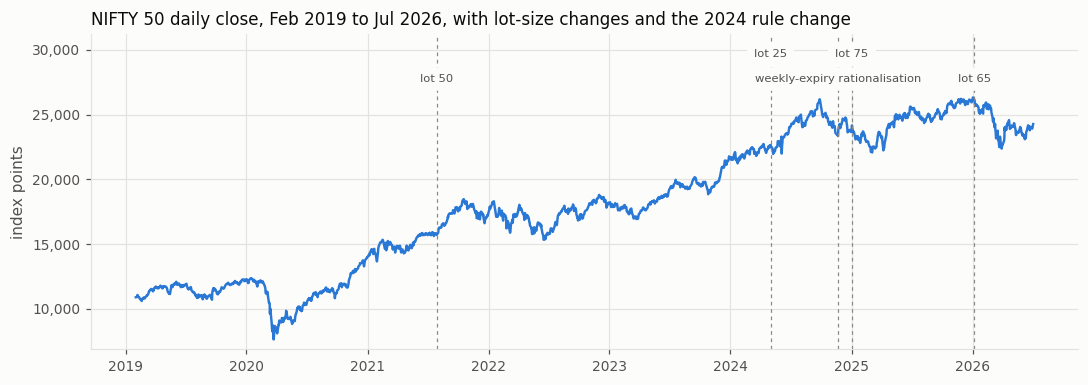

In [11]:
# Daily close of the NIFTY 50 (last regular-session bar of each day, from the cleaned bars), with market-rule changes marked.
spot = pl.read_parquet(CURATED / "market" / "nifty_spot.parquet", columns=["trade_date", "datetime", "close"])
daily = spot.drop_nulls("close").sort("datetime").group_by("trade_date").agg(pl.col("close").last()).sort("trade_date").to_pandas()
regimes = CONFIG["regimes"]
events = [(pd.Timestamp(str(l["effective_from_expiry"])), f"lot {l['units_per_lot']}") for l in regimes["lot_sizes"][1:]]
events += [(pd.Timestamp(str(m["date"])), "weekly-expiry\nrationalisation") for m in regimes.get("regime_markers", [])]

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(daily["trade_date"], daily["close"], color=BLUE)
top = daily["close"].max() * 1.04
for k, (when, label) in enumerate(sorted(events)):
    ax.axvline(when, color=NEUTRAL, linewidth=0.8, linestyle=(0, (3, 3)))
    ax.text(when, top * (1.0 if k % 2 == 0 else 1.07), label.replace("\n", " "), fontsize=7.5, color=TEXT_2, ha="center", va="bottom",
            backgroundcolor=SURFACE)
ax.set_ylim(daily["close"].min() * 0.9, top * 1.14)
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_ylabel("index points")
ax.set_title("NIFTY 50 daily close, Feb 2019 to Jul 2026, with lot-size changes and the 2024 rule change")
fig.tight_layout()
plt.show()

### 3.4 India VIX

- **Daily file:** the main control variable. It is lagged one day, so a feature only uses yesterday's close. It ends on 6 April 2026.
- **5-minute file:** optional, and only covers 2023-01 to 2026-04.

In [12]:
vix_daily = pl.read_csv(RAW / "india_vix" / "INDVIX_daily.csv.gz")
print(f"{rel(RAW / 'india_vix' / 'INDVIX_daily.csv.gz')}: {vix_daily.height:,} rows, {vix_daily['date'].min()} to {vix_daily['date'].max()}")
display(vix_daily.tail(3).to_pandas())
vix_5m = pl.read_csv(RAW / "india_vix" / "INDVIX_5minute.csv.gz")
print(f"{rel(RAW / 'india_vix' / 'INDVIX_5minute.csv.gz')}: {vix_5m.height:,} rows, {vix_5m['datetime'].min()} to {vix_5m['datetime'].max()}")
display(vix_5m.head(3).to_pandas())

data/raw/india_vix/INDVIX_daily.csv.gz: 3,266 rows, 2013-01-01 to 2026-04-06


,datetime,stock_code,open,high,low,close,volume,date
0,2026-04-01 12:04:00,INDVIX,27.89,27.89,23.65,25.01,0,2026-04-01
1,2026-04-02 12:04:00,INDVIX,25.01,26.60,25.01,25.52,0,2026-04-02
2,2026-04-06 12:04:00,INDVIX,25.52,26.56,25.08,25.47,0,2026-04-06


data/raw/india_vix/INDVIX_5minute.csv.gz: 80,636 rows, 2023-01-19 13:35:00 to 2026-04-24 16:00:00


,datetime,stock_code,open,high,low,close,volume,date
0,2023-01-19 13:35:00,INDVIX,14.09,14.10,14.08,14.09,0,2023-01-19
1,2023-01-19 13:40:00,INDVIX,14.09,14.10,14.03,14.03,0,2023-01-19
2,2023-01-19 13:45:00,INDVIX,14.03,14.06,14.02,14.02,0,2023-01-19


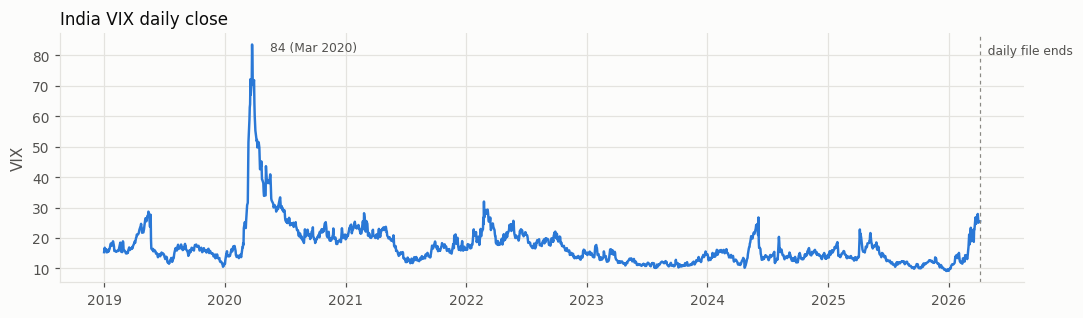

In [13]:
vix_plot = vix_daily.with_columns(pl.col("date").str.to_date()).filter(pl.col("date") >= date(2019, 1, 1)).to_pandas()
fig, ax = plt.subplots(figsize=(10, 3.0))
ax.plot(vix_plot["date"], vix_plot["close"], color=BLUE)
peak = vix_plot.loc[vix_plot["close"].idxmax()]
ax.annotate(f"{peak['close']:.0f} ({peak['date']:%b %Y})", (peak["date"], peak["close"]), xytext=(12, -4),
            textcoords="offset points", fontsize=8, color=TEXT_2)
ax.axvline(pd.Timestamp(vix_plot["date"].max()), color=NEUTRAL, linewidth=0.8, linestyle=(0, (3, 3)))
ax.text(pd.Timestamp(vix_plot["date"].max()), ax.get_ylim()[1] * 0.92, "  daily file ends", fontsize=8, color=TEXT_2)
ax.set_ylabel("VIX")
ax.set_title("India VIX daily close")
fig.tight_layout()
plt.show()

### 3.5 Participant-wise open interest (NSE)

- **Source:** every evening NSE publishes how many index and stock futures and option contracts each client type holds long and short.
- **Use:** this is the closest thing to ground truth about **which side dealers are on**. It is published after the close, so a feature can only use the previous day's figures.
- **Scope:** it covers *all* index options, not only NIFTY.

In [14]:
participant = pl.read_parquet(RAW / "fiidii" / "participant_oi_2019_to_today.parquet")
print(f"{rel(RAW / 'fiidii' / 'participant_oi_2019_to_today.parquet')}: {participant.height:,} rows "
      f"({participant['date'].n_unique():,} days x {participant['Client Type'].n_unique()} client types)")
display(participant.filter(pl.col("date") == participant["date"].max()).select(
    "date", "Client Type", "Option Index Call Long", "Option Index Call Short", "Option Index Put Long", "Option Index Put Short").to_pandas())

data/raw/fiidii/participant_oi_2019_to_today.parquet: 9,255 rows (1,851 days x 5 client types)


,date,Client Type,Option Index Call Long,Option Index Call Short,Option Index Put Long,Option Index Put Short
0,2026-07-03,Client,3096998.0,3007973.0,2747363.0,3360184.0
1,2026-07-03,DII,4090.0,835.0,26055.0,1014.0
2,2026-07-03,FII,479396.0,712869.0,921556.0,444381.0
3,2026-07-03,Pro,929076.0,787884.0,1027040.0,916435.0
4,2026-07-03,TOTAL,4509560.0,4509560.0,4722015.0,4722015.0


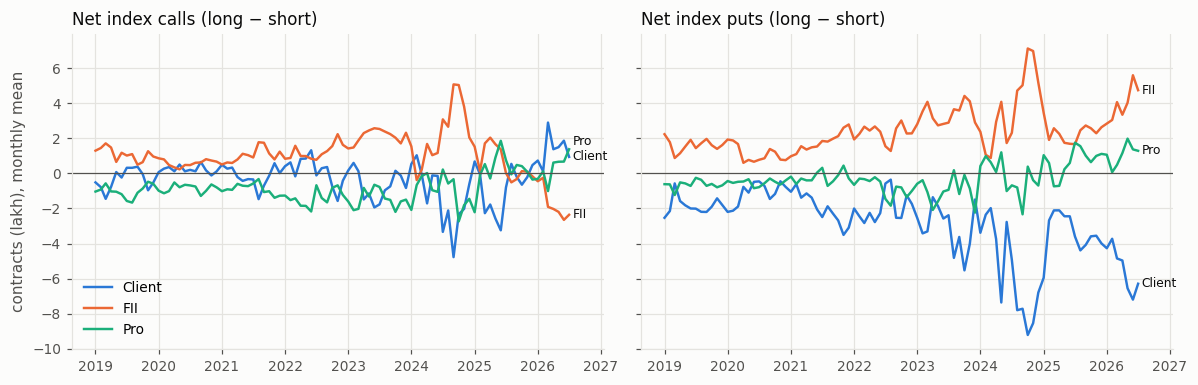

In [15]:
# Net index-option positions (long minus short contracts), monthly average, for the three client types used in the project.
net = (participant.filter(pl.col("Client Type").is_in(["Client", "FII", "Pro"]))
       .with_columns(pl.col("date").dt.truncate("1mo").alias("month"),
                     (pl.col("Option Index Call Long") - pl.col("Option Index Call Short")).alias("calls"),
                     (pl.col("Option Index Put Long") - pl.col("Option Index Put Short")).alias("puts"))
       .group_by("month", "Client Type").agg(pl.col("calls").mean(), pl.col("puts").mean()).sort("month").to_pandas())
colors = {"Client": BLUE, "FII": ORANGE, "Pro": AQUA}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, side in zip(axes, ("calls", "puts")):
    ends = []
    for who, color in colors.items():
        part = net[net["Client Type"] == who]
        ax.plot(part["month"], part[side] / 1e5, color=color, label=who)
        ends.append([part[side].iloc[-1] / 1e5, who])
    ends.sort()
    for k in range(1, len(ends)):
        ends[k][0] = max(ends[k][0], ends[k - 1][0] + 0.9)
    for y, who in ends:
        ax.text(part["month"].iloc[-1] + pd.Timedelta(days=20), y, who, fontsize=8, color=TEXT, va="center")
    ax.axhline(0, color=TEXT_2, linewidth=0.8)
    ax.set_title(f"Net index {side} (long − short)")
    ax.set_xlim(right=part["month"].iloc[-1] + pd.Timedelta(days=200))
axes[0].set_ylabel("contracts (lakh), monthly mean")
axes[0].legend(loc="lower left")
fig.tight_layout()
plt.show()

## 4. One trading day in the data: 12 June 2026

Two views of the same afternoon:

- **How the instruments move together:** the index and the front-month future over the day.
- **Where option positions sit:** open interest by strike for the nearest expiry (16 June), as known at 15:15, the model's daily snapshot.

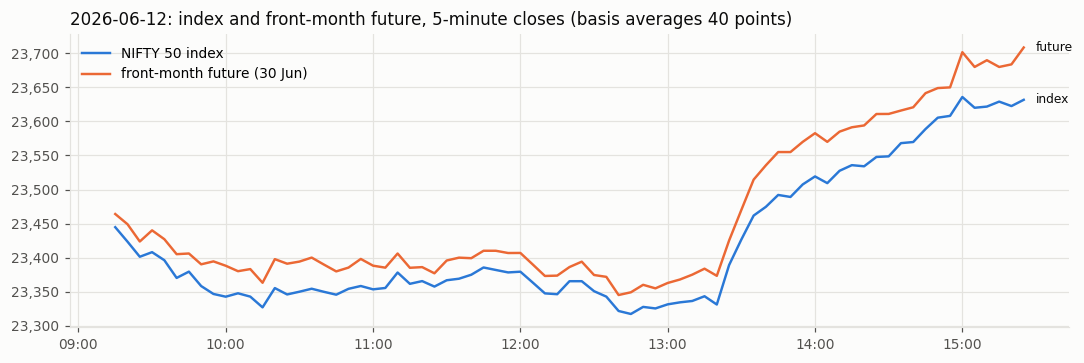

In [16]:
DAY = "2026-06-12"
day_spot = spot_raw.filter(pl.col("date") == DAY).with_columns(pl.col("datetime").str.to_datetime())
day_fut = sample_future.filter(pl.col("date") == DAY).with_columns(pl.col("datetime").str.to_datetime())
session = lambda f: f.filter(pl.col("datetime").dt.strftime("%H:%M").is_between(pl.lit("09:15"), pl.lit("15:25")))
day_spot, day_fut = session(day_spot).to_pandas(), session(day_fut).to_pandas()

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(day_spot["datetime"], day_spot["close"], color=BLUE, label="NIFTY 50 index")
ax.plot(day_fut["datetime"], day_fut["close"], color=ORANGE, label="front-month future (30 Jun)")
for frame, color, name in ((day_spot, BLUE, "index"), (day_fut, ORANGE, "future")):
    ax.text(frame["datetime"].iloc[-1] + pd.Timedelta(minutes=5), frame["close"].iloc[-1], name, fontsize=8, color=TEXT, va="center")
basis = (day_fut.set_index("datetime")["close"] - day_spot.set_index("datetime")["close"]).dropna()
ax.set_title(f"{DAY}: index and front-month future, 5-minute closes (basis averages {basis.mean():.0f} points)")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M"))
ax.legend(loc="best")
fig.tight_layout()
plt.show()

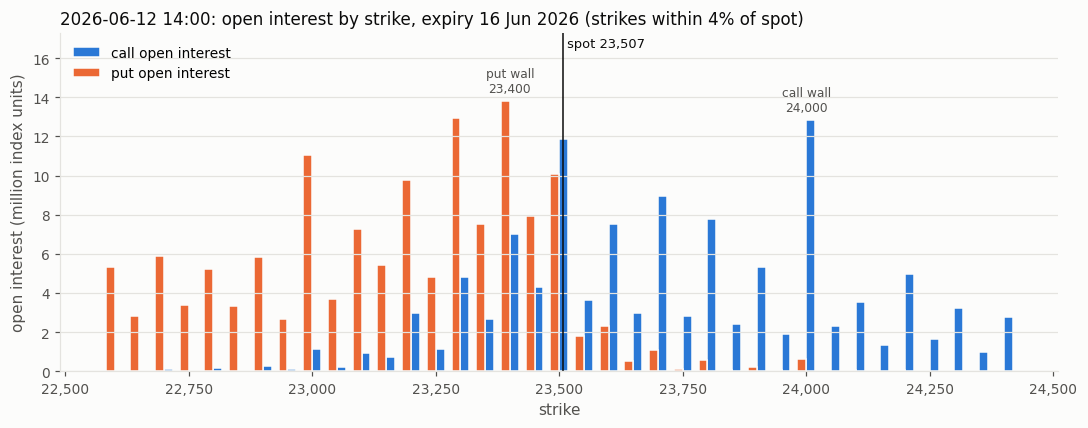

In [17]:
# Open interest by strike at 15:15 (the 15:10 bar) for the 16 June expiry: calls above, puts below.
sample_put = pl.read_csv(RAW / "options" / "NIFTY" / "2026" / f"NIFTY-put-{SAMPLE_EXPIRY}.csv.gz")
bar = "2026-06-12 15:10:00"
spot_at = float(spot_raw.filter(pl.col("datetime") == bar)["close"][0])
chain = pl.concat([sample_call, sample_put]).filter((pl.col("datetime") == bar)
                                                    & pl.col("strike_price").is_between(spot_at * 0.96, spot_at * 1.04)).to_pandas()
calls = chain[chain["right"] == "Call"].set_index("strike_price")["open_interest"]
puts = chain[chain["right"] == "Put"].set_index("strike_price")["open_interest"]
call_wall = calls[calls.index > spot_at].idxmax()
put_wall = puts[puts.index < spot_at].idxmax()

fig, ax = plt.subplots(figsize=(10, 4.0))
width = 18
ax.bar(calls.index + width / 2, calls / 1e6, width=width, color=BLUE, label="call open interest", edgecolor=SURFACE, linewidth=1)
ax.bar(puts.index - width / 2, puts / 1e6, width=width, color=ORANGE, label="put open interest", edgecolor=SURFACE, linewidth=1)
ax.set_ylim(0, max(calls.max(), puts.max()) / 1e6 * 1.25)
ax.axvline(spot_at, color=TEXT, linewidth=1)
ax.text(spot_at, ax.get_ylim()[1] * 0.99, f" spot {spot_at:,.0f}", fontsize=8.5, color=TEXT, va="top")
for strike, label in ((call_wall, "call wall"), (put_wall, "put wall")):
    ax.annotate(f"{label}\n{strike:,.0f}", (strike, max(calls.get(strike, 0), puts.get(strike, 0)) / 1e6), xytext=(0, 6),
                textcoords="offset points", ha="center", fontsize=8, color=TEXT_2)
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_xlabel("strike")
ax.set_ylabel("open interest (million index units)")
ax.grid(axis="x", visible=False)
ax.set_title(f"{DAY} 15:15: open interest by strike, expiry 16 Jun 2026 (strikes within 4% of spot)")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

## 5. Preview: what the inputs become

The pipeline turns these raw files into the quantity the project studies:

- it cleans every source to a common timeline;
- it backs out the forward and implied volatility;
- it computes gamma per strike and multiplies by open interest.

Below is the resulting **GEX profile** for the same snapshot (12 June 2026, 15:15), summed over expiries within 21 days. It uses the "naive" sign convention: calls positive, puts negative. Above the **flip level** dealers are, on this convention, net long gamma, and their hedging damps moves.

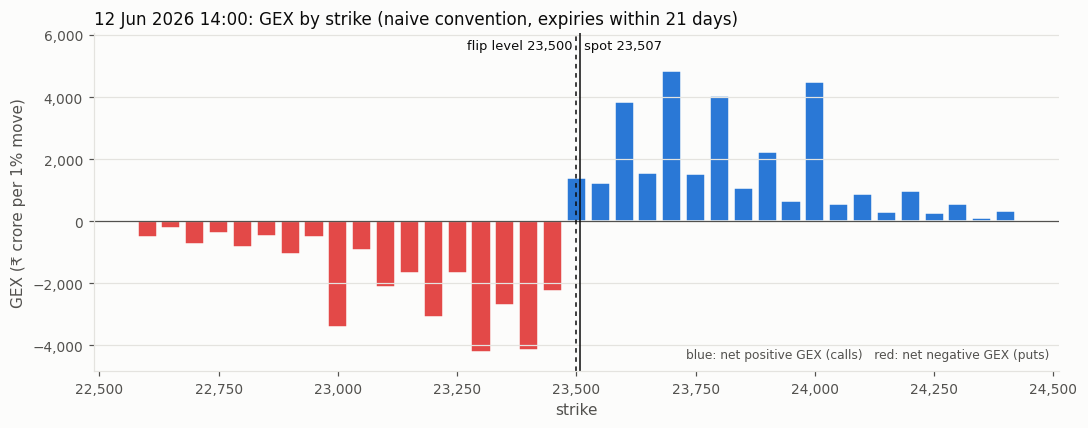

call wall 24,000   put wall 23,000   max pain 23,450   max-GEX strike 23,500


In [18]:
from zoneinfo import ZoneInfo
snap = datetime(2026, 6, 12, 15, 15, tzinfo=ZoneInfo("Asia/Kolkata"))
from niftygex.exposure.selection import total_gex_expiries

strikes = (pl.read_parquet(EXPOSURE / "gex_strikes" / "year=2026.parquet")
           .filter(pl.col("snapshot_at") == snap)
           .filter(total_gex_expiries("t2", CONFIG["data"]["gex"])))
profile = strikes.group_by("strike_price").agg(pl.col("gex_naive").sum() / 1e7).sort("strike_price").to_pandas()
level = pl.read_parquet(EXPOSURE / "levels" / "levels.parquet").filter((pl.col("snapshot_at") == snap) & (pl.col("target") == "t2")).row(0, named=True)
profile = profile[profile["strike_price"].between(level["spot"] * 0.96, level["spot"] * 1.04)]

fig, ax = plt.subplots(figsize=(10, 4.0))
colors = np.where(profile["gex_naive"] >= 0, BLUE, RED)
ax.bar(profile["strike_price"], profile["gex_naive"], width=40, color=colors, edgecolor=SURFACE, linewidth=1)
ax.axhline(0, color=TEXT_2, linewidth=0.8)
ax.set_ylim(profile["gex_naive"].min() * 1.15, profile["gex_naive"].max() * 1.25)
spot_left = level["flip_naive"] is not None and level["flip_naive"] > level["spot"]
for value, label, style, side in ((level["spot"], "spot", "-", "right" if spot_left else "left"),
                                  (level["flip_naive"], "flip level", (0, (3, 3)), "left" if spot_left else "right")):
    if value is not None:
        ax.axvline(value, color=TEXT, linewidth=1, linestyle=style)
        text = f"{label} {value:,.0f} " if side == "right" else f" {label} {value:,.0f}"
        ax.text(value, ax.get_ylim()[1] * 0.97, text, fontsize=8.5, color=TEXT, va="top", ha=side)
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.text(0.99, 0.04, "blue: net positive GEX (calls)   red: net negative GEX (puts)", transform=ax.transAxes, ha="right", fontsize=8, color=TEXT_2)
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_xlabel("strike")
ax.set_ylabel("GEX (₹ crore per 1% move)")
ax.grid(axis="x", visible=False)
ax.set_title("12 Jun 2026 15:15: GEX by strike (naive convention, expiries within 21 days)")
fig.tight_layout()
plt.show()
print(f"call wall {level['call_wall']:,.0f}   put wall {level['put_wall']:,.0f}   max pain {level['max_pain']:,.0f}   "
      f"max-GEX strike {level['max_gex_strike']:,.0f}")

## 6. Data quality and known gaps

Every gap is detected by code, flagged in the data, and never silently filled.

The table comes from `outputs/reports/missing_data.md`, which `scripts/report_missing_data.py` generates.

In [19]:
display(Markdown((REPORTS / "missing_data.md").read_text().split("\n", 4)[-1]))

Trading calendar: 1824 days, 2019-02-01 to 2026-07-03.

| Gap | Extent | Handling |
|---|---|---|
| Option OI recorded as 0 (missing) | 69 days: 2019-07-30, 2022-01-03 to 2022-04-11 (68 days) | OI nulled; GEX, OI levels, PCR, OI-change and token OI fields missing |
| Spot missing | 8 days: 2024-09-16 to 2024-09-18 (3 days), 2024-09-30 to 2024-10-01 (2 days), 2025-08-14, 2025-11-17, 2025-12-01 | not imputed; excluded from GEX spot scaling, RV and targets |
| Option data missing | 5 days: 2019-02-01, 2019-02-04, 2019-02-05, 2019-02-06, 2019-11-06 | flagged `missing_options` |
| Futures data missing | 1 days: 2022-01-18 | flagged `missing_futures` |
| Incomplete-bar days | options 10, futures 18, spot 21, vix_intraday 22 | flagged `incomplete_*_bars`; rows kept |
| Expiry file ends before its expiry day | 2022-01-06 (last data 2021-12-31) | no expiry-day chain for that contract |
| Option history per expiry | median 21, max 21 calendar days | GEX horizon set to 21 days |
| Daily India VIX | ends 2026-04-06; 60 trading days without: 2026-04-07 to 2026-07-03 (60 days) | NaN, never forward-filled |
| Intraday India VIX | 2023-01-19 to 2026-04-24; 1033 trading days without | optional source |
| Participant OI | missing trading days: none | NaN, never forward-filled |
| Spot bad prints | 1: 2021-10-18 12:50:00+05:30 | OHLC nulled |
| Spot/futures alignment exceptions | 2025-12-05 (best lag -1, corr 0.36) | erratic futures closes; no relabel |
| Bhavcopy | absent | 15:25 OI proxy used; reconciliation skipped |
| Official NSE closing index (T1) | absent | T1 cannot run |


## 7. Summary

In [20]:
features = json.loads((REPORTS / "features_report.json").read_text())
tokens = json.loads((REPORTS / "tokens_report.json").read_text())
calendar = pl.read_parquet(CURATED / "calendar" / "trading_calendar.parquet").filter(pl.col("observed"))
summary = pd.DataFrame([
    ("Raw files / size", f"{manifest['file_count']} files, {manifest['total_size_bytes'] / 1e6:,.0f} MB"),
    ("Project window", f"{start:%Y-%m-%d} to {end:%Y-%m-%d} ({calendar.height:,} trading days)"),
    ("Option expiries", f"{len(expiries)}"),
    ("Option bar-rows (raw → cleaned)", f"{cleaning['row_counts']['options']['raw_rows']:,} → {cleaning['row_counts']['options']['after_required_fields']:,}"),
    ("Snapshot feature rows (one per trading day, 15:15)", f"{features['rows']:,}"),
    ("Per-strike tokens", f"{tokens['rows']:,} (median ~{int(tokens['tokens_per_snapshot_by_target']['t2']['median'])} per snapshot)"),
], columns=["", "value"])
show(summary)

,value
Raw files / size,"881 files, 378 MB"
Project window,"2019-02-01 to 2026-07-03 (1,824 trading days)"
Option expiries,393
Option bar-rows (raw → cleaned),"22,878,869 → 22,428,331"
Snapshot feature rows (T1/T2/T3),"4,803"
Per-strike tokens,"327,009 (median ~71 per snapshot)"
